# DS201 – Deep Learning trong Khoa học Dữ liệu
## Lab 4 – Encoder–Decoder và Attention cho dịch máy
### Phần C. Bài tập về nhà

### Mục tiêu
Xây dựng mô hình dịch máy Anh → Việt từ đầu bằng PyTorch, huấn luyện trên small-PhoMT và đánh giá công bằng ba kiến trúc:

1. **Bài 1:** Encoder–Decoder LSTM không attention.
2. **Bài 2:** Encoder–Decoder LSTM với Bahdanau additive attention.
3. **Bài 3:** Encoder–Decoder LSTM với Luong global-general attention và input-feeding.


### Tổ chức notebook
1. Chuẩn bị môi trường và dữ liệu Kaggle.
2. Tiền xử lý, từ điển, DataLoader.
3. Kiến trúc chung, attention và kiểm thử.
4. ROUGE-L, quy trình huấn luyện và chọn checkpoint.
5. Huấn luyện lần lượt Bài 1, 2, 3.
6. Đánh giá test cuối, phân tích 3 bản dịch mỗi mô hình và 3 heatmap Bahdanau.
7. Tổng hợp kết quả C.2, lưu sản phẩm và hướng dẫn nộp bài.

## 1. Chuẩn bị môi trường trên Kaggle

### 1.1. Tải dữ liệu


In [1]:
import importlib.util, subprocess, sys
packages = {'rouge_score': 'rouge-score', 'sacrebleu': 'sacrebleu'}
missing = [pkg for module, pkg in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

In [2]:
import hashlib, json, random, time, unicodedata, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import (
    pad_sequence, pack_padded_sequence, pad_packed_sequence,
)
from torch.utils.data import DataLoader
from rouge_score import rouge_scorer
from sacrebleu.metrics import BLEU

# Cố định seed và chọn thiết bị
def seed_all(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_all()
torch.set_num_threads(min(4, torch.get_num_threads()))
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| device:', device)
from IPython.display import display, Markdown
from tqdm.auto import tqdm
import gc
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('Cảnh báo: nên bật GPU trên Kaggle trước khi huấn luyện đủ 3 mô hình.')

PyTorch: 2.11.0+cu130 | device: cuda
GPU: Tesla T4


### 1.2. Cấu hình chung 

| Thông số | Giá trị |
|---|---:|
| Số lớp LSTM encoder / decoder | 3 / 3 |
| Hidden size / embedding | 256 / 256 |
| Dropout | 0.3 |
| Optimizer / learning rate | Adam / 0.001 |
| Batch size | 32 |
| Teacher forcing ratio | 0.5 |
| Số epoch | 10 |
| Độ dài tối đa mỗi phía | 50 token trước BOS/EOS |
| Giới hạn mỗi từ điển | 10.000 (gồm 4 token đặc biệt) |
| Tần suất token tối thiểu | 2 |
| Train / dev / test | Toàn bộ sau lọc |
| Seed | 42 |

Các mô hình có cùng encoder, dữ liệu, thứ tự batch, siêu tham số và greedy decoding. Checkpoint được chọn bằng ROUGE-L dev lớn nhất, nếu hòa chọn dev-NLL nhỏ nhất. Không chọn bằng test.

In [3]:
cfg = dict(emb=256, hidden=256, layers=3, dropout=0.3,
           batch=32, lr=1e-3, teacher_ratio=0.5, epochs=10,
           max_words=50, vocab_limit=10000, min_freq=2,
           train_limit=None, dev_limit=None)
PAD, UNK, BOS, EOS = 0, 1, 2, 3
MODES = ['none', 'bahdanau', 'luong']
LABELS = {'none': 'Bài 1. Không attention', 'bahdanau': 'Bài 2. Bahdanau', 'luong': 'Bài 3. Luong'}
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
display(pd.DataFrame(cfg.items(), columns=['Thông số', 'Giá trị']))

,Thông số,Giá trị
0,emb,256.000
1,hidden,256.000
2,layers,3.000
3,dropout,0.300
4,batch,32.000
5,lr,0.001
6,teacher_ratio,0.500
7,epochs,10.000
8,max_words,50.000
9,vocab_limit,10000.000


### 1.3. Tìm dữ liệu và kiểm tra SHA-256



In [4]:
INPUT = Path('/kaggle/input')
ART = Path('/kaggle/working/lab4_artifacts')
ART.mkdir(parents=True, exist_ok=True)
SPLITS = ['train', 'dev', 'test']

DATA_DIR = None
EXPECTED_SHA256 = {
    'train': 'f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde965d60c0a213d3906cba',
    'dev': 'fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786decc544ae90de1c23f9',
    'test': '1c63903af344ead37b85e2a51487e71bf44c0ceed7797b5979a9551282d83d1a'
}

files = {}
if DATA_DIR is not None:
    files = {s: Path(DATA_DIR) / f'small-{s}.json' for s in SPLITS}
else:
    for s in SPLITS:
        matches = sorted(INPUT.rglob(f'small-{s}.json'))
        if len(matches) != 1:
            raise FileNotFoundError(f'{s}: tìm thấy {len(matches)} tệp: {matches}. '
                                    'Hãy Add Input hoặc chỉ định DATA_DIR.')
        files[s] = matches[0]
    if len({v.parent for v in files.values()}) != 1:
        raise ValueError('Ba tệp phải cùng một thư mục dataset gốc; chỉ định DATA_DIR.')
DATA_FILES = []
for s, path in files.items():
    if not path.is_file():
        raise FileNotFoundError(path)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    expected = EXPECTED_SHA256[s]
    if expected is not None and digest.lower() != expected.lower():
        raise ValueError(f'Checksum không khớp: {path}')
    DATA_FILES.append(dict(split=s, file=path.name, path=str(path), sha256=digest,
                           expected_sha256=expected, verified=expected is not None))
display(pd.DataFrame(DATA_FILES))
if not all(x['verified'] for x in DATA_FILES):
    print('Đã tính checksum, nhưng chưa đối chiếu được tất cả với mã SHA-256 chuẩn.')

,split,file,path,sha256,expected_sha256,verified
0,train,small-train.json,/kaggle/input/datasets/thyvxun/small-phomt/sma...,f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde96...,f643c83f1ce3c9781eb5e03ed3ea56406abd4d877fde96...,True
1,dev,small-dev.json,/kaggle/input/datasets/thyvxun/small-phomt/sma...,fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786d...,fceab11b93c92167887c90f22ccc2f08c9ac8cb1c7786d...,True
2,test,small-test.json,/kaggle/input/datasets/thyvxun/small-phomt/sma...,1c63903af344ead37b85e2a51487e71bf44c0ceed7797b...,1c63903af344ead37b85e2a51487e71bf44c0ceed7797b...,True


## 2. Tiền xử lý dữ liệu

### 2.1. Chuẩn hóa, lọc và kiểm tra dữ liệu

Mỗi tệp là JSON array có hai trường `english` và `vietnamese`. Chuẩn hóa Unicode NFC, bỏ BOM, chuyển chữ thường và tách khoảng trắng (không bỏ dấu tiếng Việt). Chỉ giữ cặp có cả hai phía từ 1 đến 50 token, không cắt cụt câu. Giữ ID gốc để truy xuất kết quả. Số lượng yêu cầu: train 18.607, dev 1.901, test 1.786. Test chỉ được dùng để đánh giá sau khi đã khóa các checkpoint.

In [5]:
# Chuẩn hóa: bỏ BOM, NFC, chữ thường, tách theo khoảng trắng
def tokens(text):
    text = unicodedata.normalize('NFC', text.replace('﻿', ''))
    return text.lower().split()

print(tokens('Tôi YÊU bạn'))
raw, filtered = {}, {}
expected_raw = dict(train=20000, dev=2000, test=2000)
expected_filtered = dict(train=18607, dev=1901, test=1786)
stats = []
for split in SPLITS:
    raw[split] = json.loads(files[split].read_text(encoding='utf-8-sig'))
    assert isinstance(raw[split], list) and len(raw[split]) == expected_raw[split], split
    filtered[split] = []
    for i, row in enumerate(raw[split]):
        assert isinstance(row, dict) and all(isinstance(row.get(k), str) for k in ['english','vietnamese']), (split,i)
        source, target = tokens(row['english']), tokens(row['vietnamese'])
        if 1 <= len(source) <= cfg['max_words'] and 1 <= len(target) <= cfg['max_words']:
            filtered[split].append(dict(id=i, src=source, tgt=target))
    assert len(filtered[split]) == expected_filtered[split], (split, len(filtered[split]))
    stats.append({'split': split, 'gốc':len(raw[split]), 'sau lọc':len(filtered[split]),
                  'loại':len(raw[split])-len(filtered[split])})
display(pd.DataFrame(stats))
print('Schema và số lượng dữ liệu: PASS')

['tôi', 'yêu', 'bạn']


,split,gốc,sau lọc,loại
0,train,20000,18607,1393
1,dev,2000,1901,99
2,test,2000,1786,214


Schema và số lượng dữ liệu: PASS


### 2.2. Xây dựng từ điển Anh và Việt

Chỉ xây từ điển bằng **train sau lọc** để tránh rò rỉ dữ liệu. Sắp theo tần suất giảm dần, nếu bằng nhau sắp theo token. Token có tần suất nhỏ hơn 2 hoặc nằm ngoài giới hạn từ điển được ánh xạ sang UNK.

| Token | ID | Vai trò |
|---|---:|---|
| `<pad>` | 0 | Đệm các câu trong batch |
| `<unk>` | 1 | Token ngoài từ điển |
| `<bos>` | 2 | Bắt đầu câu đích |
| `<eos>` | 3 | Kết thúc câu |

Câu tham chiếu để chấm điểm giữ nguyên token gốc đã chuẩn hóa, không thay từ lạ bằng UNK.

In [6]:
# Hàm xây từ điển: 4 token đặc biệt + token xuất hiện ít nhất min_freq lần
SPECIAL = ['<pad>', '<unk>', '<bos>', '<eos>']
def make_vocab(sequences):
    freq = Counter(t for seq in sequences for t in seq)
    ranked = sorted(freq, key=lambda t: (-freq[t], t))
    keep = [t for t in ranked if freq[t] >= cfg['min_freq']
            and t not in SPECIAL][:cfg['vocab_limit']-4]
    return {token: i for i, token in enumerate(SPECIAL+keep)}

# Từ điển tiếng Anh (nguồn) và tiếng Việt (đích)
src_vocab = make_vocab(r['src'] for r in filtered['train'])
tgt_vocab = make_vocab(r['tgt'] for r in filtered['train'])
tgt_itos = {i: t for t, i in tgt_vocab.items()}
assert all(src_vocab[t] == tgt_vocab[t] == i
           for i, t in enumerate(SPECIAL))
print('Từ điển Anh/Việt:', len(src_vocab), len(tgt_vocab))
print('Special IDs:', {t: src_vocab[t] for t in SPECIAL})

# Đổi token thành id; token chưa có trong từ điển phải thành UNK
def encode(seq, vocab):
    return [vocab.get(t, UNK) for t in seq]

assert encode(['từ_không_có_thật'], tgt_vocab) == [UNK]
print('encode:', encode(['tôi', 'từ_không_có_thật'], tgt_vocab))

Từ điển Anh/Việt: 8943 4003
Special IDs: {'<pad>': 0, '<unk>': 1, '<bos>': 2, '<eos>': 3}
encode: [6, 1]


### 2.3. Batch, padding và dịch nhãn một bước

Câu nguồn thêm EOS. Câu đích thêm BOS và EOS. Các tensor được pad bên phải; độ dài nguồn thật dùng cho packing. Ví dụ: đích `[BOS, tôi, yêu, bạn, EOS]` có input `[BOS, tôi, yêu, bạn]` và nhãn `[tôi, yêu, bạn, EOS]`. Loss không chấm BOS và PAD. Mỗi DataLoader train có generator seed 42 riêng, bảo đảm ba mô hình duyệt các batch cùng thứ tự qua các epoch.

In [7]:
# Ghép batch: nguồn thêm EOS, đích thêm BOS/EOS, đệm PAD bên phải
def collate(rows):
    src = [torch.tensor(encode(r['src'], src_vocab)+[EOS]) for r in rows]
    tgt = [torch.tensor([BOS]+encode(r['tgt'], tgt_vocab)+[EOS])
           for r in rows]
    return dict(
        src=pad_sequence(src, batch_first=True, padding_value=PAD),
        lengths=torch.tensor([len(x) for x in src]),
        tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD),
        refs=[' '.join(r['tgt']) for r in rows],
        ids=[r['id'] for r in rows],
    )

# Thử trên hai cặp câu tự tạo
toy = [dict(id=-1, src=tokens('i love you'), tgt=tokens('tôi yêu bạn')),
       dict(id=-2, src=tokens('hello'), tgt=tokens('xin chào'))]
batch = collate(toy)
print('src:', tuple(batch['src'].shape),
      '| lengths:', batch['lengths'].tolist())
print('tgt:', tuple(batch['tgt'].shape))

# Decoder đọc tgt[:, :-1] để dự đoán tgt[:, 1:] (lệch một bước)
decoder_input = [tgt_itos[i] for i in batch['tgt'][0, :-1].tolist()]
target = [tgt_itos[i] for i in batch['tgt'][0, 1:].tolist()]
print('decoder input:', decoder_input)
print('target       :', target)
assert batch['tgt'][:, :-1].shape == batch['tgt'][:, 1:].shape

# Lấy tập con cố định theo seed 42; limit=None nghĩa là dùng toàn bộ
def choose(rows, limit):
    if limit is None or len(rows) <= limit:
        return rows
    ids = np.random.default_rng(42).permutation(len(rows))[:limit]
    return [rows[int(i)] for i in ids]

train_rows = choose(filtered['train'], cfg['train_limit'])
dev_rows = choose(filtered['dev'], cfg['dev_limit'])
print('Train/dev đang dùng:', len(train_rows), len(dev_rows))

# DataLoader có generator cố định để thứ tự batch giống nhau giữa các mô hình
def loader(rows, shuffle=False):
    return DataLoader(rows, batch_size=cfg['batch'], shuffle=shuffle,
                      collate_fn=collate,
                      generator=torch.Generator().manual_seed(42))

print('Số batch train mỗi epoch:', len(loader(train_rows)))

src: (2, 4) | lengths: [4, 2]
tgt: (2, 5)
decoder input: ['<bos>', 'tôi', 'yêu', 'bạn']
target       : ['tôi', 'yêu', 'bạn', '<eos>']
Train/dev đang dùng: 18607 1901
Số batch train mỗi epoch: 582


## 3. Xây dựng kiến trúc mô hình

### 3.1. Encoder LSTM chung (3 lớp)



In [8]:
# Encoder: Embedding -> LSTM có packing; trả memory và (h, c)
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn = nn.LSTM(emb, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)

    def forward(self, src, lengths):
        packed = pack_padded_sequence(
            self.drop(self.emb(src)), lengths.cpu(),
            batch_first=True, enforce_sorted=False)
        packed_out, state = self.rnn(packed)
        memory, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=src.size(1))
        return memory, state

# Chạy thử encoder trên batch tự tạo và xem shape
model_cfg = {k: cfg[k] for k in ['emb', 'hidden', 'layers', 'dropout']}
encoder = Encoder(len(src_vocab), **model_cfg).to(device)
memory, (h, c) = encoder(batch['src'].to(device), batch['lengths'])
print('memory:', tuple(memory.shape))
print('h/c:', tuple(h.shape), tuple(c.shape))

memory: (2, 4, 256)
h/c: (3, 2, 256) (3, 2, 256)


### 3.2. Hai cơ chế attention

Với query $q_t$, key/value $m_i$ lấy từ memory encoder:

- **Bahdanau (additive):** $e_{ti}=v^\top\tanh(W_q q_t+W_k m_i)$, query là hidden state ở bước trước.
- **Luong (general):** $e_{ti}=q_t^\top W m_i$, query là hidden state ở bước hiện tại.

Mask gán điểm tại PAD bằng $-\infty$. Trọng số và context:

$$\alpha_{ti}=\frac{\exp(e_{ti})}{\sum_j\exp(e_{tj})},\qquad c_t=\sum_i\alpha_{ti}m_i.$$

Mỗi hàng trọng số cộng bằng 1; PAD nhận trọng số 0. Context không thay thế cell state của LSTM. Để giảm phép tính lặp lại khi chạy đủ 10 epoch, phép chiếu tuyến tính memory được tính một lần cho mỗi batch rồi dùng lại ở mọi bước decoder (không thay đổi công thức).

In [9]:
# Hai kiểu tính điểm: Bahdanau (cộng) và Luong general (nhân)
class Attention(nn.Module):
    def __init__(self, hidden, mode):
        super().__init__()
        self.mode = mode
        if mode == 'bahdanau':
            self.Wq = nn.Linear(hidden, hidden, bias=False)
            self.Wk = nn.Linear(hidden, hidden, bias=False)
            self.v = nn.Linear(hidden, 1, bias=False)
        elif mode == 'luong':
            self.W = nn.Linear(hidden, hidden, bias=False)
        else:
            raise ValueError(mode)

    def project(self, memory):
        return self.Wk(memory) if self.mode == 'bahdanau' else self.W(memory)

    def forward(self, query, memory, mask, projected=None):
        if projected is None:
            projected = self.project(memory)
        if self.mode == 'bahdanau':
            energy = torch.tanh(self.Wq(query).unsqueeze(1)
                                + projected)
            scores = self.v(energy).squeeze(-1)
        else:
            scores = torch.bmm(projected,
                               query.unsqueeze(2)).squeeze(2)
        scores = scores.masked_fill(~mask, float('-inf'))
        weights = torch.softmax(scores, dim=-1)
        context = torch.bmm(weights.unsqueeze(1), memory).squeeze(1)
        return context, weights

# Kiểm tra: trọng số mỗi câu cộng bằng 1 và bằng 0 tại vị trí PAD
mask = batch['src'].to(device) != PAD
for mode in ['bahdanau', 'luong']:
    attn = Attention(cfg['hidden'], mode).to(device)
    context, weights = attn(h[-1], memory, mask)
    ones = torch.ones(len(toy), device=device)
    assert torch.allclose(weights.sum(-1), ones)
    assert torch.all(weights.masked_select(~mask) == 0)
    print(mode, '| context:', tuple(context.shape), '| mask: PASS')

bahdanau | context: (2, 256) | mask: PASS
luong | context: (2, 256) | mask: PASS


### 3.3. Decoder cho ba bài tập

| Mô hình | Input LSTM tại bước t | Vị trí attention |
|---|---|---|
| Không attention | Embedding token | Không dùng memory trực tiếp |
| Bahdanau | Embedding + context từ hidden trước đó | Trước khi cập nhật LSTM |
| Luong | Embedding + attentional vector ở bước trước | Sau khi cập nhật LSTM |

Với attention, hidden hiện tại và context được ghép, chiếu tuyến tính qua `tanh`, rồi đưa qua output head để dự đoán token. Riêng Luong sử dụng vector này làm input-feeding ở bước sau, khởi tạo bằng 0 ở bước đầu. Cả ba sử dụng decoder 3 lớp, hidden size 256.

In [10]:
# Decoder chạy từng bước; mode = 'none', 'bahdanau' hoặc 'luong'
class Decoder(nn.Module):
    def __init__(self, vocab_size, mode, emb, hidden, layers, dropout):
        super().__init__()
        self.mode = mode
        self.emb = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        width = emb if mode == 'none' else emb + hidden
        self.rnn = nn.LSTM(width, hidden, layers, batch_first=True,
                           dropout=dropout if layers > 1 else 0.0)
        if mode != 'none':
            self.attn = Attention(hidden, mode)
            self.fuse = nn.Linear(2*hidden, hidden)
        self.head = nn.Linear(hidden, vocab_size)

    def step(self, token, state, memory, mask, feeding, projected=None):
        embedded = self.drop(self.emb(token))
        weights = None
        if self.mode == 'bahdanau':
            context, weights = self.attn(state[0][-1], memory, mask, projected)
            rnn_input = torch.cat([embedded, context], dim=-1)
        elif self.mode == 'luong':
            rnn_input = torch.cat([embedded, feeding], dim=-1)
        else:
            rnn_input = embedded
        out, state = self.rnn(rnn_input.unsqueeze(1), state)
        query = out[:, 0]
        if self.mode == 'luong':
            context, weights = self.attn(query, memory, mask, projected)
        if self.mode != 'none':
            feeding = torch.tanh(self.fuse(torch.cat([query, context], -1)))
            query = feeding
        logits = self.head(self.drop(query))
        return logits, state, feeding, weights

### 3.4. Seq2Seq và teacher forcing



In [11]:
# Seq2Seq = Encoder + Decoder; teacher_ratio là xác suất dùng token đúng
class Seq2Seq(nn.Module):
    def __init__(self, mode, src_size, tgt_size, **kwargs):
        super().__init__()
        self.mode = mode
        self.encoder = Encoder(src_size, **kwargs)
        self.decoder = Decoder(tgt_size, mode, **kwargs)
        self.hidden = kwargs['hidden']

    def forward(self, src, lengths, tgt, teacher_ratio=0.5):
        memory, state = self.encoder(src, lengths)
        mask = src != PAD
        projected = self.decoder.attn.project(memory) if self.mode != "none" else None
        token = tgt[:, 0]
        feeding = memory.new_zeros(src.size(0), self.hidden)
        logits = []
        for t in range(1, tgt.size(1)):
            step, state, feeding, _ = self.decoder.step(
                token, state, memory, mask, feeding, projected)
            logits.append(step)
            coin = torch.rand(src.size(0), device=src.device)
            predicted = step.argmax(-1).detach()
            token = torch.where(coin < teacher_ratio, tgt[:, t], predicted)
        return torch.stack(logits, dim=1)

# Kiểm tra shape logits của ba mô hình
def make_seq2seq(mode, **kwargs):
    kwargs = kwargs or model_cfg
    return Seq2Seq(mode, len(src_vocab), len(tgt_vocab), **kwargs).to(device)

### 3.5. Greedy decoding

Bắt đầu từ BOS, lấy token có logit lớn nhất (loại PAD và BOS). Mỗi câu kết thúc khi sinh EOS, hoặc khi đạt 51 bước (50 token + EOS). Hàm `generate` không nhận target. ROUGE-L được tính trên câu tự sinh chứ không dùng teacher forcing. Heatmap lấy từ trọng số trong quá trình sinh token.

In [12]:
# Sinh từng token bằng argmax đến khi mọi câu gặp EOS hoặc hết max_steps
@torch.no_grad()
def generate(model, src, lengths, max_steps):
    model.eval()
    memory, state = model.encoder(src, lengths)
    mask = src != PAD
    projected = model.decoder.attn.project(memory) if model.mode != "none" else None
    token = torch.full((src.size(0),), BOS, device=src.device)
    feeding = memory.new_zeros(src.size(0), model.hidden)
    finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    outputs, all_weights = [], []
    for _ in range(max_steps):
        logits, state, feeding, weights = model.decoder.step(
            token, state, memory, mask, feeding, projected)
        logits[:, [PAD, BOS]] = float('-inf')
        token = logits.argmax(-1)
        token = torch.where(finished, torch.full_like(token, EOS), token)
        outputs.append(token)
        if weights is not None:
            all_weights.append(weights)
        finished = finished | (token == EOS)
        if bool(finished.all()):
            break
    ids = torch.stack(outputs, dim=1)
    weights = torch.stack(all_weights, dim=1) if all_weights else None
    return ids, weights

# Đổi dãy id thành câu, dừng ở EOS và bỏ PAD/BOS
def decode(ids):
    words = []
    for value in ids:
        i = int(value)
        if i == EOS:
            break
        if i not in {PAD, BOS}:
            words.append(tgt_itos[i])
    return ' '.join(words)

print('decode:', decode(batch['tgt'][0]))

decode: tôi yêu bạn


### 3.6. Kiểm thử tính đúng đắn trước khi huấn luyện



In [13]:
# Hàm loss bỏ qua vị trí PAD của câu đích
criterion = nn.CrossEntropyLoss(ignore_index=PAD)
with torch.no_grad():
    for mode in MODES:
        seed_all()
        m = make_seq2seq(mode).eval()
        assert m.encoder.rnn.num_layers == m.decoder.rnn.num_layers == cfg['layers']
        x, y = batch['src'].to(device), batch['tgt'].to(device)
        lengths = batch['lengths']
        a = m(x, lengths, y, teacher_ratio=1.0)
        b = m(nn.functional.pad(x, (0, 12), value=PAD), lengths, y, teacher_ratio=1.0)
        assert a.shape == (y.size(0), y.size(1)-1, len(tgt_vocab))
        torch.testing.assert_close(a, b, atol=1e-5, rtol=1e-4)
        gold = y[:, 1:]
        more_gold = nn.functional.pad(gold, (0,2), value=PAD)
        extra = torch.randn(a.size(0), 2, a.size(2), device=device)
        l1 = criterion(a.reshape(-1,a.size(-1)), gold.reshape(-1))
        l2 = criterion(torch.cat([a,extra],1).reshape(-1,a.size(-1)), more_gold.reshape(-1))
        torch.testing.assert_close(l1,l2)
        ids, weights = generate(m, x, lengths, max_steps=5)
        assert ids.shape[1] <= 5 and not ((ids==PAD)|(ids==BOS)).any()
        if weights is not None:
            torch.testing.assert_close(weights.sum(-1), torch.ones_like(weights.sum(-1)))
            assert (weights.masked_select((x==PAD).unsqueeze(1).expand_as(weights)) == 0).all()
        print(mode, '| shape, padding, loss, greedy, mask: PASS')
        del m, a, b, ids, weights, extra
assert 'tgt' not in generate.__code__.co_varnames
# Giải phóng tensor/mô hình kiểm tra riêng, không dùng lại trọng số khi train.
del encoder, memory, h, c, attn, context, mask
gc.collect()
if device.type == "cuda": torch.cuda.empty_cache()

none | shape, padding, loss, greedy, mask: PASS
bahdanau | shape, padding, loss, greedy, mask: PASS
luong | shape, padding, loss, greedy, mask: PASS


## 4. Độ đo và quy trình huấn luyện

### 4.1. ROUGE-L giữ dấu tiếng Việt



In [14]:
# ROUGE-L với tokenizer giữ dấu tiếng Việt, không stemming
class UnicodeTokens:
    def tokenize(self, text):
        return tokens(text)

rouge = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=False,
                                 tokenizer=UnicodeTokens())
print(UnicodeTokens().tokenize('Tiếng Việt có dấu'))

# Trung bình ROUGE-L theo câu, kèm BLEU corpus để tham khảo
def translation_metrics(hypotheses, references):
    assert len(hypotheses) == len(references) > 0
    scores = [rouge.score(ref, hyp)['rougeL']
              for hyp, ref in zip(hypotheses, references)]
    bleu = BLEU(tokenize='none', lowercase=False)
    value = bleu.corpus_score(hypotheses, [references])
    return dict(
        rougeL_f1=float(np.mean([s.fmeasure for s in scores])),
        rougeL_precision=float(np.mean([s.precision for s in scores])),
        rougeL_recall=float(np.mean([s.recall for s in scores])),
        bleu=value.score, bleu_signature=str(bleu.get_signature()))

# Kiểm tra: câu dịch trùng câu tham chiếu thì ROUGE-L F1 = 1
example = translation_metrics(['tôi yêu bạn'], ['tôi yêu bạn'])
assert example['rougeL_f1'] == 1.0
print('ROUGE-L F1 khi khớp hoàn toàn:', example['rougeL_f1'])

['tiếng', 'việt', 'có', 'dấu']
ROUGE-L F1 khi khớp hoàn toàn: 1.0


### 4.2. Hàm đánh giá

- Dev-NLL: negative log-likelihood trung bình trên token đích không phải PAD, dùng teacher forcing 1.0 để đánh giá xác suất điều kiện.
- ROUGE-L/BLEU: dùng greedy decoding chỉ nhận câu nguồn, cả dev lẫn test.
- Ở lần chấm test cuối, lưu từng dự đoán kèm ID, điểm câu, trạng thái EOS để phân tích định tính mà không cần chấm lại tập test.
- Với Bahdanau, lưu ma trận attention của đúng lần giải mã test để vẽ heatmap khớp hoàn toàn với bản dịch đã ghi nhận.

In [15]:
@torch.no_grad()
def evaluate(model, rows, compute_nll=True, return_predictions=False, attention_cache=None):
    model.eval()
    hypotheses, references, records = [], [], []
    row_by_id = {r['id']: r for r in rows}
    nll, count = 0.0, 0
    for b in loader(rows):
        src = b['src'].to(device)
        if compute_nll:
            tgt = b['tgt'].to(device)
            target = tgt[:,1:]
            logits = model(src, b['lengths'], tgt, teacher_ratio=1.0)
            nll += nn.functional.cross_entropy(logits.reshape(-1,len(tgt_vocab)),
                       target.reshape(-1), ignore_index=PAD, reduction='sum').item()
            count += int((target != PAD).sum())
            del logits
        generated, weights = generate(model, src, b['lengths'], cfg['max_words']+1)
        for i, (rid, seq, ref) in enumerate(zip(b['ids'], generated.cpu().tolist(), b['refs'])):
            hyp = decode(seq)
            hypotheses.append(hyp)
            references.append(ref)
            if attention_cache is not None:
                assert weights is not None
                stop = seq.index(EOS)+1 if EOS in seq else len(seq)
                matrix = weights[i,:stop,:int(b['lengths'][i])].cpu().numpy().copy()
                attention_cache[rid] = (seq[:stop], matrix)
            if return_predictions:
                records.append(dict(id=rid, source=' '.join(row_by_id[rid]['src']),
                                    reference=ref, prediction=hyp, eos=EOS in seq,
                                    sentence_rougeL=rouge.score(ref,hyp)['rougeL'].fmeasure))
    metrics = translation_metrics(hypotheses,references)
    if compute_nll:
        metrics['dev_nll'] = nll/count
    if return_predictions:
        return metrics, pd.DataFrame(records)
    return metrics

### 4.3. Huấn luyện và chọn checkpoint

Loss là cross entropy trung bình theo token không PAD. Adam cập nhật tham số sau backpropagation và gradient clipping (norm tối đa 1.0). Tính train loss theo số token thật, không lấy trung bình không trọng số giữa các batch. Đo thời gian chỉ phần train, không gồm dev evaluation. Mỗi epoch lưu history và checkpoint tốt nhất ngay khi có cải thiện. Không early stopping để đảm bảo đủ 10 epoch.

In [16]:
# Huấn luyện một epoch, trả loss trung bình trên token thật
def train_epoch(model, train_loader, optimizer):
    model.train()
    loss_total, tokens_total = 0.0, 0
    for b in tqdm(train_loader, desc='Train', leave=False):
        src, tgt = b['src'].to(device), b['tgt'].to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(src, b['lengths'], tgt, cfg['teacher_ratio'])
        gold = tgt[:, 1:]
        loss = criterion(logits.reshape(-1, len(tgt_vocab)),
                         gold.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        n = int((gold != PAD).sum())
        loss_total += loss.item()*n
        tokens_total += n
    return loss_total/tokens_total

In [17]:
def fit(model, name):
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    train_loader = loader(train_rows, shuffle=True)
    best_key, best_epoch = (-1., float('-inf')), 0
    history = []
    for epoch in range(1, cfg['epochs']+1):
        seed_all(42+epoch)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss = train_epoch(model, train_loader, optimizer)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        seconds = time.perf_counter()-start
        measured = evaluate(model, dev_rows)
        key = (measured['rougeL_f1'], -measured['dev_nll'])
        if key > best_key:
            best_key, best_epoch = key, epoch
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            torch.save(best_state, ART/f'{name}.pt')
        history.append(dict(epoch=epoch, train_loss=train_loss, seconds=seconds, **measured))
        pd.DataFrame(history).to_csv(ART/f'history_{name}.csv', index=False)
        print(f'{name} | epoch {epoch:02d}/{cfg["epochs"]} | loss={train_loss:.4f} | '
              f'dev ROUGE-L={measured["rougeL_f1"]:.4f} | dev NLL={measured["dev_nll"]:.4f} | '
              f'BLEU={measured["bleu"]:.2f} | train={seconds:.1f}s | best epoch={best_epoch}')
    model.load_state_dict(torch.load(ART/f'{name}.pt', map_location=device, weights_only=True))
    model.eval()
    return history, best_epoch

histories, best_epochs, parameters = {}, {}, {}

def train_model(mode):
    seed_all(42)
    model = make_seq2seq(mode)
    parameters[mode] = sum(p.numel() for p in model.parameters())
    print(LABELS[mode], '| Số tham số:', f'{parameters[mode]:,}')
    histories[mode], best_epochs[mode] = fit(model, mode)
    del model
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()

# Nạp checkpoint theo nhu cầu, không giữ cả 3 mô hình trên GPU cùng lúc.
def load_model(mode):
    model = make_seq2seq(mode)
    model.load_state_dict(torch.load(ART/f'{mode}.pt', map_location=device, weights_only=True))
    return model.eval()

def plot_history(mode):
    h = pd.DataFrame(histories[mode])
    fig, axes = plt.subplots(1, 2, figsize=(12,4))
    for ax, col, title in zip(axes, ['train_loss','rougeL_f1'],
                              ['Train loss / token', 'Dev ROUGE-L F1 (greedy)']):
        ax.plot(h.epoch, h[col], marker='o')
        ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_xticks(h.epoch)
        ax.grid(alpha=.25)
    axes[1].axvline(best_epochs[mode], ls='--', label='Best checkpoint')
    axes[1].legend()
    fig.suptitle(LABELS[mode]); fig.tight_layout()
    fig.savefig(ART/f'learning_curves_{mode}.png', dpi=180, bbox_inches='tight')
    plt.show(); plt.close(fig)
    display(h[['epoch','train_loss','rougeL_f1','dev_nll','bleu','seconds']].round(4))
    print('Best epoch:',best_epochs[mode])

## 5. Bài 1 – Không attention

Baseline nén toàn bộ câu nguồn vào hai trạng thái cuối h và c. Decoder không truy cập memory tại mỗi bước; câu dài có thể tạo nút thắt thông tin.

### Huấn luyện, checkpoint và đồ thị
Khởi tạo từ seed 42, chạy đủ 10 epoch trên toàn bộ train, lựa chọn checkpoint bằng dev. Đồ thị loss và ROUGE-L dev cùng bảng lịch sử được xuất tự động. Phần test và ba câu mẫu của bài này nằm ở mục 9–10 sau khi cả ba mô hình đã được chốt.

In [18]:
train_model('none')

Bài 1. Không attention | Số tham số: 7,500,963


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none | epoch 01/10 | loss=6.0187 | dev ROUGE-L=0.1239 | dev NLL=5.8887 | BLEU=0.06 | train=68.9s | best epoch=1


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (21 outputs left out)

none | epoch 09/10 | loss=4.9452 | dev ROUGE-L=0.2293 | dev NLL=4.8577 | BLEU=2.16 | train=66.8s | best epoch=9


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


none | epoch 10/10 | loss=4.8821 | dev ROUGE-L=0.2281 | dev NLL=4.8127 | BLEU=2.30 | train=67.2s | best epoch=9


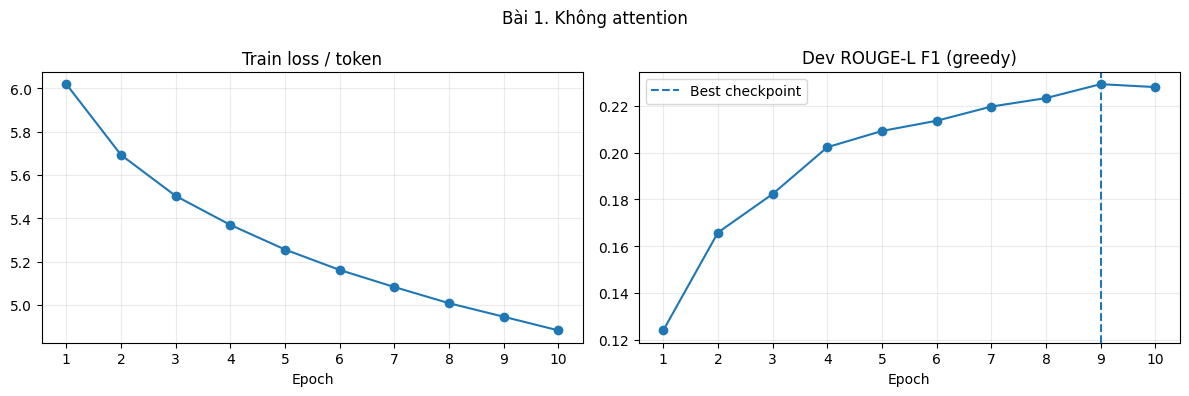

,epoch,train_loss,rougeL_f1,dev_nll,bleu,seconds
0,1,6.0187,0.1239,5.8887,0.0606,68.9015
1,2,5.6920,0.1658,5.5813,0.6209,68.4383
2,3,5.5027,0.1823,5.4021,1.0123,66.8667
3,4,5.3690,0.2023,5.2596,1.3390,67.5601
4,5,5.2554,0.2093,5.1470,1.4614,67.7667
5,6,5.1610,0.2136,5.0500,1.6003,67.3442
6,7,5.0822,0.2197,4.9761,1.8967,67.8285
7,8,5.0076,0.2234,4.9149,1.9340,67.4367
8,9,4.9452,0.2293,4.8577,2.1649,66.7734
9,10,4.8821,0.2281,4.8127,2.3034,67.2397


Best epoch: 9


In [19]:
plot_history('none')

## 6. Bài 2 – Bahdanau

Decoder dùng additive attention, tính context từ hidden của bước trước và nối vào embedding trước khi cập nhật LSTM. Có thể tập trung vào các vị trí nguồn khác nhau khi sinh từng token.

### Huấn luyện, checkpoint và đồ thị
Khởi tạo từ seed 42, chạy đủ 10 epoch trên toàn bộ train, lựa chọn checkpoint bằng dev. Đồ thị loss và ROUGE-L dev cùng bảng lịch sử được xuất tự động. Phần test và ba câu mẫu của bài này nằm ở mục 9–10 sau khi cả ba mô hình đã được chốt.

In [20]:
train_model('bahdanau')

Bài 2. Bahdanau | Số tham số: 8,025,763


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau | epoch 01/10 | loss=6.0384 | dev ROUGE-L=0.1068 | dev NLL=5.9055 | BLEU=0.17 | train=102.2s | best epoch=1


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (21 outputs left out)

bahdanau | epoch 09/10 | loss=4.5685 | dev ROUGE-L=0.2878 | dev NLL=4.5331 | BLEU=4.24 | train=101.8s | best epoch=9


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


bahdanau | epoch 10/10 | loss=4.4865 | dev ROUGE-L=0.2927 | dev NLL=4.4829 | BLEU=4.37 | train=101.9s | best epoch=10


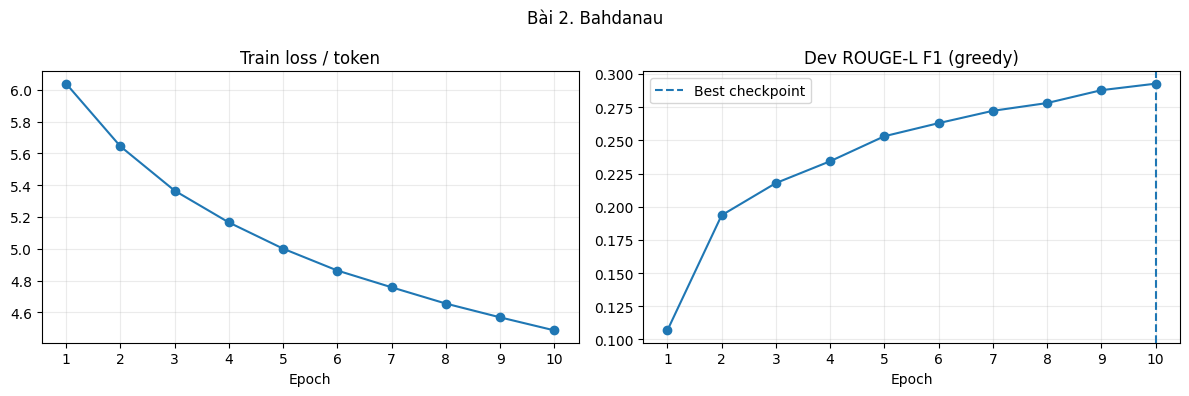

,epoch,train_loss,rougeL_f1,dev_nll,bleu,seconds
0,1,6.0384,0.1068,5.9055,0.1675,102.2459
1,2,5.6442,0.1935,5.4726,1.1005,102.6357
2,3,5.3654,0.2178,5.2309,1.6192,102.0611
3,4,5.1654,0.2342,5.0535,2.2231,102.3528
4,5,5.0005,0.2531,4.8861,2.6820,101.9913
5,6,4.8629,0.2630,4.7614,3.1074,101.9672
6,7,4.7575,0.2722,4.6784,3.5776,102.5185
7,8,4.6551,0.2781,4.5955,3.8197,102.5212
8,9,4.5685,0.2878,4.5331,4.2418,101.8009
9,10,4.4865,0.2927,4.4829,4.3739,101.9245


Best epoch: 10


In [21]:
plot_history('bahdanau')

## 7. Bài 3 – Luong

Decoder dùng global-general attention sau khi LSTM cập nhật và input-feeding từ bước trước. Cấu hình khác được giữ nguyên để đối chiếu với Bài 1 và Bài 2.

### Huấn luyện, checkpoint và đồ thị
Khởi tạo từ seed 42, chạy đủ 10 epoch trên toàn bộ train, lựa chọn checkpoint bằng dev. Đồ thị loss và ROUGE-L dev cùng bảng lịch sử được xuất tự động. Phần test và ba câu mẫu của bài này nằm ở mục 9–10 sau khi cả ba mô hình đã được chốt.

In [22]:
train_model('luong')

Bài 3. Luong | Số tham số: 7,959,971


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong | epoch 01/10 | loss=6.0632 | dev ROUGE-L=0.1345 | dev NLL=5.9354 | BLEU=0.18 | train=92.1s | best epoch=1


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


... (21 outputs left out)

luong | epoch 09/10 | loss=4.5635 | dev ROUGE-L=0.2968 | dev NLL=4.5184 | BLEU=4.84 | train=92.0s | best epoch=9


Train:   0%|          | 0/582 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


luong | epoch 10/10 | loss=4.4763 | dev ROUGE-L=0.3005 | dev NLL=4.4651 | BLEU=4.95 | train=92.5s | best epoch=10


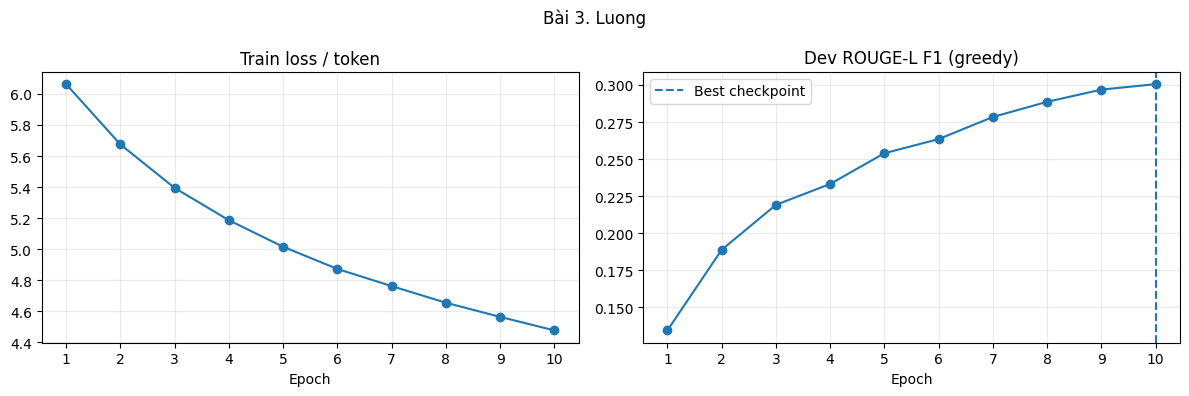

,epoch,train_loss,rougeL_f1,dev_nll,bleu,seconds
0,1,6.0632,0.1345,5.9354,0.1768,92.0650
1,2,5.6746,0.1888,5.5358,1.0538,92.5459
2,3,5.3944,0.2191,5.2682,1.7167,92.0601
3,4,5.1863,0.2332,5.0727,2.3819,91.8269
4,5,5.0152,0.2540,4.9071,3.0081,92.0757
5,6,4.8724,0.2635,4.8050,3.2924,92.6853
6,7,4.7619,0.2784,4.6953,4.0245,92.4950
7,8,4.6546,0.2886,4.5939,4.4414,92.2789
8,9,4.5635,0.2968,4.5184,4.8431,91.9605
9,10,4.4763,0.3005,4.4651,4.9466,92.5159


Best epoch: 10


In [23]:
plot_history('luong')

## 8. So sánh dev và khóa checkpoint trước test



In [24]:
assert set(histories) == set(MODES) and all(len(histories[m]) == cfg['epochs'] for m in MODES)
dev_records = []
for mode in MODES:
    h = pd.DataFrame(histories[mode])
    best = h.loc[h.epoch == best_epochs[mode]].iloc[0]
    dev_records.append(dict(model=mode, dev_rougeL=best.rougeL_f1, dev_bleu=best.bleu,
                            dev_nll=best.dev_nll, best_epoch=best_epochs[mode],
                            parameters=parameters[mode], seconds_per_epoch=h.seconds.mean()))
comparison_dev = pd.DataFrame(dev_records)
comparison_dev.to_csv(ART/'comparison_dev.csv', index=False)
display(comparison_dev.round(4))
metadata = dict(config=cfg, seed=42, device=str(device), torch_version=torch.__version__,
                normalization='NFC; remove BOM; lowercase; whitespace',
                special_ids=dict(zip(SPECIAL,[PAD,UNK,BOS,EOS])),
                src_vocab=src_vocab, tgt_vocab=tgt_vocab, files=DATA_FILES,
                selected_train_ids=[r['id'] for r in train_rows],
                selected_dev_ids=[r['id'] for r in dev_rows],
                selected_test_ids=[r['id'] for r in filtered['test']],
                histories=histories, best_epochs=best_epochs, parameters=parameters)
(ART/'metadata.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2), encoding='utf-8')
# Nạp hai bản checkpoint độc lập, kiểm tra tensor và logits sau round-trip.
restored = load_model('bahdanau')
with torch.no_grad():
    args = (batch['src'].to(device),batch['lengths'],batch['tgt'].to(device))
    before = restored(*args,teacher_ratio=1.0)
    tmp = ART/'_reload_check.pt'
    torch.save(restored.state_dict(),tmp)
    another = make_seq2seq('bahdanau').eval()
    another.load_state_dict(torch.load(tmp,map_location=device,weights_only=True))
    torch.testing.assert_close(before,another(*args,teacher_ratio=1.0))
    tmp.unlink()
del restored,another,before
print('Checkpoint và metadata đã được lưu; kiểm tra nạp lại: PASS')

,model,dev_rougeL,dev_bleu,dev_nll,best_epoch,parameters,seconds_per_epoch
0,none,0.2293,2.1649,4.8577,9,7500963,67.6156
1,bahdanau,0.2927,4.3739,4.4829,10,8025763,102.2019
2,luong,0.3005,4.9466,4.4651,10,7959971,92.2509


Checkpoint và metadata đã được lưu; kiểm tra nạp lại: PASS


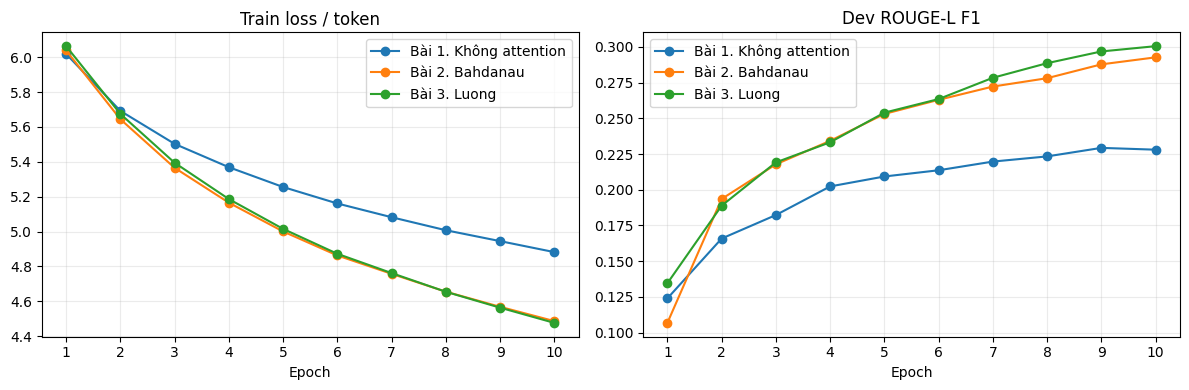

In [25]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
for mode in MODES:
    h = pd.DataFrame(histories[mode])
    axes[0].plot(h.epoch,h.train_loss,marker='o',label=LABELS[mode])
    axes[1].plot(h.epoch,h.rougeL_f1,marker='o',label=LABELS[mode])
for ax,title in zip(axes,['Train loss / token','Dev ROUGE-L F1']):
    ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_xticks(range(1,cfg['epochs']+1)); ax.grid(alpha=.25); ax.legend()
fig.tight_layout(); fig.savefig(ART/'learning_curves.png',dpi=180,bbox_inches='tight'); plt.show(); plt.close(fig)

## 9. Đánh giá cuối trên toàn bộ test (Bài 1–3)



In [26]:
test_records, predictions = [], {}
bahdanau_attention = {}
for mode in MODES:
    model = load_model(mode)
    metrics, pred = evaluate(model, filtered['test'], compute_nll=False, return_predictions=True,
                             attention_cache=bahdanau_attention if mode == 'bahdanau' else None)
    assert len(pred) == len(filtered['test']) and pred.id.is_unique
    np.testing.assert_allclose(pred.sentence_rougeL.mean(), metrics['rougeL_f1'])
    test_records.append(dict(model=mode, **metrics))
    predictions[mode] = pred
    pred.to_csv(ART/f'predictions_test_{mode}.csv', index=False, encoding='utf-8-sig')
    print(LABELS[mode], '| Test ROUGE-L F1:', round(metrics['rougeL_f1'],4))
    del model
    if device.type == 'cuda': torch.cuda.empty_cache()
comparison_test = pd.DataFrame(test_records)
comparison_test.to_csv(ART/'comparison_test.csv',index=False)
display(comparison_test.drop(columns='bleu_signature').round(4))

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Bài 1. Không attention | Test ROUGE-L F1: 0.233


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Bài 2. Bahdanau | Test ROUGE-L F1: 0.3044


That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


Bài 3. Luong | Test ROUGE-L F1: 0.3135


,model,rougeL_f1,rougeL_precision,rougeL_recall,bleu
0,none,0.2330,0.2650,0.2106,2.5311
1,bahdanau,0.3044,0.3263,0.2894,5.4427
2,luong,0.3135,0.3352,0.2984,6.3707


## 10. Ba câu dịch mẫu cho mỗi mô hình (Bài 1, 2, 3)

Chọn ba câu khác nhau từ dự đoán test đã lưu

In [27]:
def pick_examples(df):
    ranked = df.sort_values(['sentence_rougeL','id'],ascending=[False,True]).reset_index(drop=True)
    assert len(ranked) >= 3
    picks = ranked.iloc[[0,len(ranked)//2,len(ranked)-1]].copy()
    picks.insert(0,'group',['Điểm cao','Trung vị','Điểm thấp'])
    return picks

def comment_translation(row):
    ref, hyp = tokens(row.reference), tokens(row.prediction)
    if ref == hyp:
        return 'Khớp hoàn toàn câu tham chiếu; đúng về mặt đối chiếu văn bản.'
    missing = list((Counter(ref)-Counter(hyp)).elements())
    extra = list((Counter(hyp)-Counter(ref)).elements())
    msgs = [f'ROUGE-L={row.sentence_rougeL:.4f}; {len(hyp)}/{len(ref)} token (sinh/tham chiếu).']
    if not hyp: msgs.append('Mô hình sinh câu rỗng.')
    if missing: msgs.append('Token tham chiếu không xuất hiện đủ: ' + ', '.join(missing[:12]) + '.')
    if extra: msgs.append('Token dư/khác tham chiếu: ' + ', '.join(extra[:12]) + '.')
    if not missing and not extra: msgs.append('Cùng đa tập token nhưng khác thứ tự.')
    if '<unk>' in hyp: msgs.append('Có UNK, dấu hiệu mất thông tin từ vựng.')
    if any(a==b for a,b in zip(hyp,hyp[1:])): msgs.append('Có token lặp liên tiếp; cần kiểm tra tính tự nhiên.')
    if not row.eos: msgs.append('Không sinh EOS trước giới hạn giải mã.')
    msgs.append('Cần đối chiếu ngữ nghĩa với câu nguồn; khác tham chiếu chưa đủ để khẳng định dịch sai.')
    return ' '.join(msgs)

samples = {}
for mode in MODES:
    picked = pick_examples(predictions[mode])
    picked['comment'] = [comment_translation(row) for row in picked.itertuples()]
    samples[mode] = picked
    display(Markdown('### '+LABELS[mode]))
    for row in picked.itertuples():
        print(f'{row.group} | ID {row.id} | ROUGE-L {row.sentence_rougeL:.4f}')
        print('EN  :',row.source)
        print('REF :',row.reference)
        print('PRED:',row.prediction or '(rỗng)')
        print('Nhận xét:',row.comment,'\n')
    picked.to_csv(ART/f'samples_{mode}.csv',index=False,encoding='utf-8-sig')

### Bài 1. Không attention

Điểm cao | ID 822 | ROUGE-L 1.0000
EN  : ( applause )
REF : ( vỗ tay )
PRED: ( vỗ tay )
Nhận xét: Khớp hoàn toàn câu tham chiếu; đúng về mặt đối chiếu văn bản. 

Trung vị | ID 380 | ROUGE-L 0.2105
EN  : you look at something like " west wing " twitter , in which you have these fictional characters that engage with the real world .
REF : bạn hãy nhìn một số thứ như " west wing " trên twitter , những gì bạn có là những nhân vật hư cấu đó khớp với thế giới thực tại .
PRED: bạn có một một " " " " " " " " không có một một một một một một một một một một .
Nhận xét: ROUGE-L=0.2105; 25/32 token (sinh/tham chiếu). Token tham chiếu không xuất hiện đủ: bạn, hãy, nhìn, số, thứ, như, west, wing, trên, twitter, ,, những. Token dư/khác tham chiếu: có, một, một, một, một, một, một, một, một, một, một, một. Có token lặp liên tiếp; cần kiểm tra tính tự nhiên. Cần đối chiếu ngữ nghĩa với câu nguồn; khác tham chiếu chưa đủ để khẳng định dịch sai. 

Điểm thấp | ID 1304 | ROUGE-L 0.0000
EN  : vitalism bega

### Bài 2. Bahdanau

Điểm cao | ID 822 | ROUGE-L 1.0000
EN  : ( applause )
REF : ( vỗ tay )
PRED: ( vỗ tay )
Nhận xét: Khớp hoàn toàn câu tham chiếu; đúng về mặt đối chiếu văn bản. 

Trung vị | ID 1008 | ROUGE-L 0.2821
EN  : to see the universe in its full spectrum , we need to have the right eyes , and that means using special telescopes that can help us see beyond visible light .
REF : để nhìn thấy vũ trụ với tất cả quang phổ , chúng ta phải dùng đúng mắt , nghĩa là , dùng kính thiên văn đặc biệt có thể giúp chúng ta nhìn thấy những ánh sáng ngoài vùng khả kiến .
PRED: để nhìn ra các sự của của sự , , , chúng ta cần phải là , và và có thể có thể , và có thể có thể có thể có thể có thể .
Nhận xét: ROUGE-L=0.2821; 36/42 token (sinh/tham chiếu). Token tham chiếu không xuất hiện đủ: nhìn, thấy, thấy, vũ, trụ, với, tất, cả, quang, phổ, chúng, ta. Token dư/khác tham chiếu: ra, các, sự, sự, của, của, ,, ,, cần, và, và, và. Có token lặp liên tiếp; cần kiểm tra tính tự nhiên. Cần đối chiếu ngữ nghĩa với câu nguồn

### Bài 3. Luong

Điểm cao | ID 468 | ROUGE-L 0.9000
EN  : we can see everything on wikipedia .
REF : chúng ta có thể thấy mọi thứ trên wikipedia .
PRED: chúng ta có thể thấy mọi thứ trên nhau .
Nhận xét: ROUGE-L=0.9000; 10/10 token (sinh/tham chiếu). Token tham chiếu không xuất hiện đủ: wikipedia. Token dư/khác tham chiếu: nhau. Cần đối chiếu ngữ nghĩa với câu nguồn; khác tham chiếu chưa đủ để khẳng định dịch sai. 

Trung vị | ID 566 | ROUGE-L 0.2979
EN  : a female kangaroo can often simultaneously support one inside her uterus and another in her pouch .
REF : một con chuột túi cái có thể nuôi đồng thời một con non trong tử cung và một con non khác trong túi .
PRED: một người nữ có thể có thể được được một một một một một một và và và trong một cô ấy .
Nhận xét: ROUGE-L=0.2979; 23/24 token (sinh/tham chiếu). Token tham chiếu không xuất hiện đủ: con, con, con, chuột, túi, túi, cái, nuôi, đồng, thời, non, non. Token dư/khác tham chiếu: một, một, một, một, một, người, nữ, có, thể, được, được, và. Có token

## 11. Bài 2 – Heatmap attention của ba câu Bahdanau

Dùng đúng ba mẫu Bahdanau đã chọn ở mục 10.

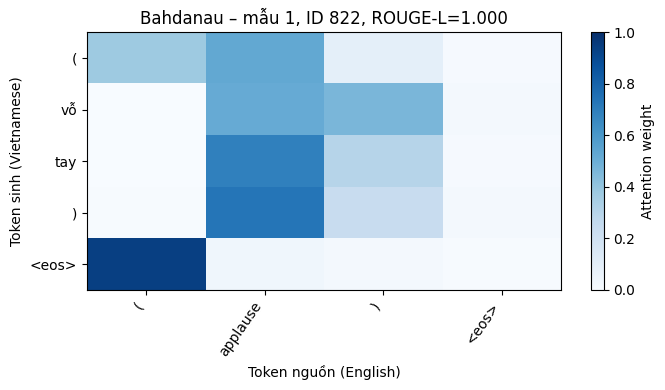

Nguồn: ( applause ) | Tham chiếu: ( vỗ tay ) | Sinh: ( vỗ tay )


,token sinh,token nguồn trọng số max,max weight,tổng trọng số
0,(,applause,0.5255,1.0
1,vỗ,applause,0.5144,1.0
2,tay,applause,0.6891,1.0
3,),applause,0.7342,1.0
4,<eos>,(,0.9395,1.0


Nhận xét: Trọng số cực đại trung bình 0.681 (phân phối đều: 0.250); các đỉnh rơi vào 2/4 vị trí nguồn. Token nhận attention trung bình cao nhất: applause. Đối chiếu bảng token và lỗi dịch ở mục 10 để nhận xét liệu các vùng tập trung có hợp lý; không coi trọng số lớn là căn chỉnh chính xác.


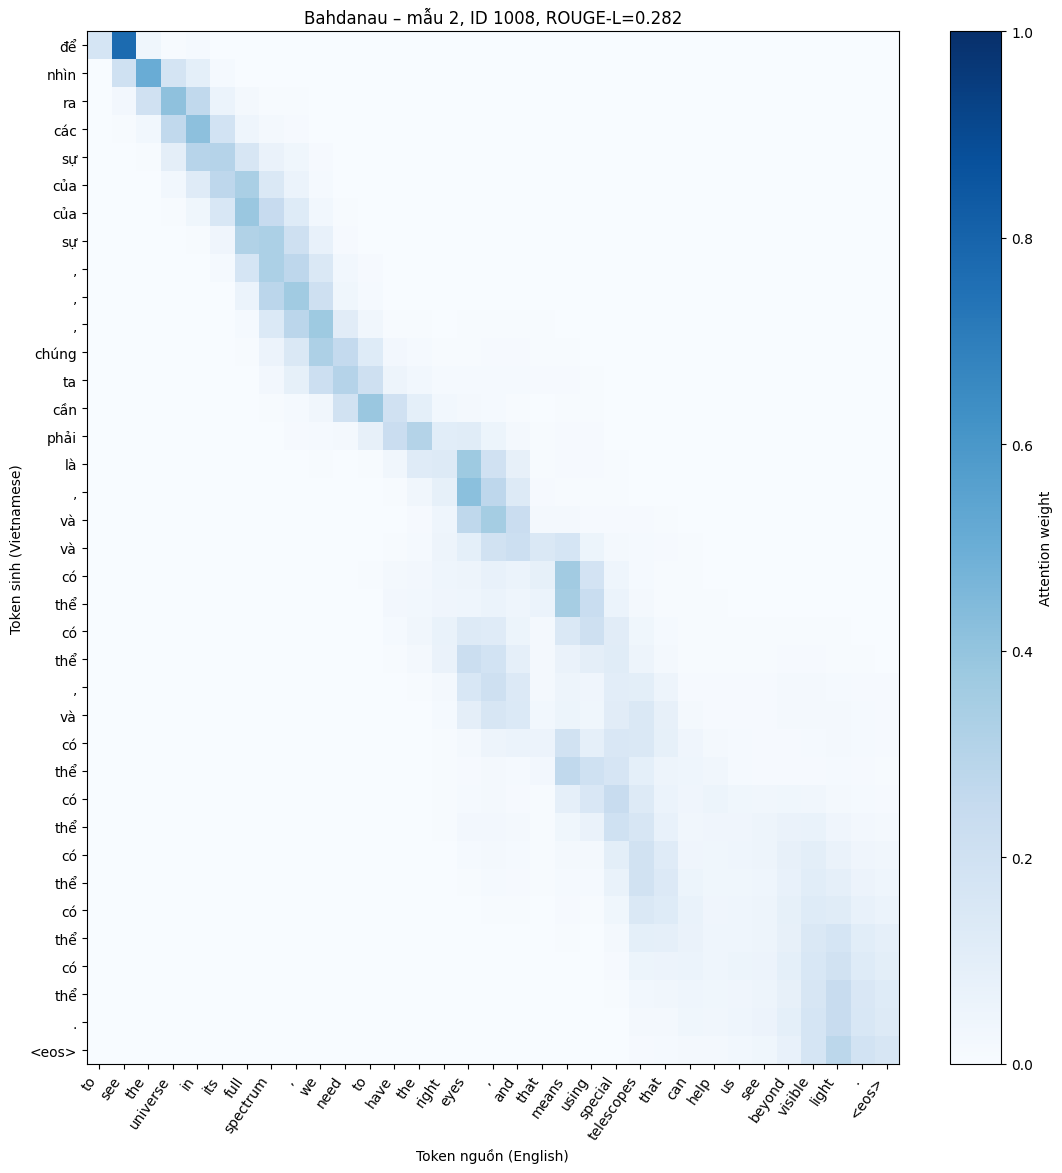

Nguồn: to see the universe in its full spectrum , we need to have the right eyes , and that means using special telescopes that can help us see beyond visible light . | Tham chiếu: để nhìn thấy vũ trụ với tất cả quang phổ , chúng ta phải dùng đúng mắt , nghĩa là , dùng kính thiên văn đặc biệt có thể giúp chúng ta nhìn thấy những ánh sáng ngoài vùng khả kiến . | Sinh: để nhìn ra các sự của của sự , , , chúng ta cần phải là , và và có thể có thể , và có thể có thể có thể có thể có thể .


,token sinh,token nguồn trọng số max,max weight,tổng trọng số
0,để,see,0.7710,1.0
1,nhìn,the,0.5072,1.0
2,ra,universe,0.4139,1.0
3,các,in,0.4164,1.0
4,sự,its,0.3022,1.0
5,của,full,0.3393,1.0
6,của,full,0.3863,1.0
7,sự,spectrum,0.3299,1.0
8,",",spectrum,0.3295,1.0
9,",",",",0.3637,1.0


Nhận xét: Trọng số cực đại trung bình 0.304 (phân phối đều: 0.030); các đỉnh rơi vào 20/33 vị trí nguồn. Token nhận attention trung bình cao nhất: eyes. Đối chiếu bảng token và lỗi dịch ở mục 10 để nhận xét liệu các vùng tập trung có hợp lý; không coi trọng số lớn là căn chỉnh chính xác.


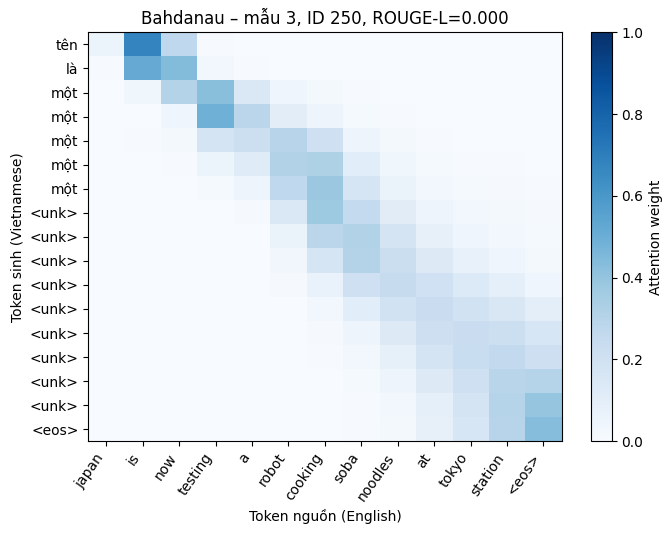

Nguồn: japan is now testing a robot cooking soba noodles at tokyo station | Tham chiếu: nhật bản thử nghiệm robot nấu mỳ soba tại nhà ga tokyo | Sinh: tên là một một một một một <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>


,token sinh,token nguồn trọng số max,max weight,tổng trọng số
0,tên,is,0.6725,1.0
1,là,is,0.5151,1.0
2,một,testing,0.4254,1.0
3,một,testing,0.4883,1.0
4,một,robot,0.2967,1.0
5,một,cooking,0.3204,1.0
6,một,cooking,0.3804,1.0
7,<unk>,cooking,0.3740,1.0
8,<unk>,soba,0.3124,1.0
9,<unk>,soba,0.3060,1.0


Nhận xét: Trọng số cực đại trung bình 0.364 (phân phối đều: 0.077); các đỉnh rơi vào 10/13 vị trí nguồn. Token nhận attention trung bình cao nhất: cooking. Đối chiếu bảng token và lỗi dịch ở mục 10 để nhận xét liệu các vùng tập trung có hợp lý; không coi trọng số lớn là căn chỉnh chính xác.


In [28]:
by_id = {r['id']:r for r in filtered['test']}
heatmap_records = []
for j, sample in enumerate(samples['bahdanau'].itertuples(),1):
    row = by_id[sample.id]
    seq, matrix = bahdanau_attention[sample.id]
    stop = len(seq)
    assert decode(seq) == sample.prediction
    np.testing.assert_allclose(matrix.sum(axis=1),1.0,atol=1e-6)
    x_labels = row['src']+['<eos>']
    y_labels = [tgt_itos[t] for t in seq[:stop]]
    assert matrix.shape == (len(y_labels),len(x_labels))
    fig,ax = plt.subplots(figsize=(max(7,.34*len(x_labels)),max(4,.32*len(y_labels))))
    im = ax.imshow(matrix,cmap='Blues',aspect='auto',vmin=0,vmax=1)
    ax.set_xticks(range(len(x_labels)),x_labels,rotation=55,ha='right')
    ax.set_yticks(range(len(y_labels)),y_labels)
    ax.set_xlabel('Token nguồn (English)'); ax.set_ylabel('Token sinh (Vietnamese)')
    ax.set_title(f'Bahdanau – mẫu {j}, ID {sample.id}, ROUGE-L={sample.sentence_rougeL:.3f}')
    fig.colorbar(im,ax=ax,label='Attention weight'); fig.tight_layout()
    fig.savefig(ART/f'attention_bahdanau_{j}.png',dpi=180,bbox_inches='tight'); plt.show(); plt.close(fig)
    print('Nguồn:',sample.source,'| Tham chiếu:',sample.reference,'| Sinh:',decode(seq))
    peak = matrix.argmax(axis=1)
    alignment = pd.DataFrame({'token sinh':y_labels,'token nguồn trọng số max':[x_labels[i] for i in peak],
                              'max weight':matrix.max(axis=1),'tổng trọng số':matrix.sum(axis=1)})
    display(alignment.round(4))
    avg_peak = float(matrix.max(axis=1).mean())
    baseline = 1/len(x_labels)
    top_source = x_labels[int(matrix.mean(axis=0).argmax())]
    n_distinct = len(set(peak.tolist()))
    comment = (f'Trọng số cực đại trung bình {avg_peak:.3f} (phân phối đều: {baseline:.3f}); '
               f'các đỉnh rơi vào {n_distinct}/{len(x_labels)} vị trí nguồn. '
               f'Token nhận attention trung bình cao nhất: {top_source}. '
               'Đối chiếu bảng token và lỗi dịch ở mục 10 để nhận xét liệu các vùng tập trung có hợp lý; '
               'không coi trọng số lớn là căn chỉnh chính xác.')
    print('Nhận xét:',comment)
    heatmap_records.append(dict(id=sample.id,mean_peak=avg_peak,uniform_weight=baseline,
                                top_source=top_source,distinct_peak_positions=n_distinct,comment=comment))
    alignment.to_csv(ART/f'attention_alignment_{j}.csv',index=False,encoding='utf-8-sig')
    np.save(ART/f'attention_matrix_{j}.npy',matrix)
pd.DataFrame(heatmap_records).to_csv(ART/'attention_analysis.csv',index=False,encoding='utf-8-sig')

## 12. Tổng hợp và nhận xét ba mô hình



In [29]:
summary = comparison_dev.merge(comparison_test[['model','rougeL_f1']],on='model',validate='one_to_one')
summary = summary.rename(columns={'rougeL_f1':'test_rougeL'})
summary['model_label'] = summary.model.map(LABELS)
required_table = summary[['model_label','dev_rougeL','test_rougeL','parameters','seconds_per_epoch']].rename(columns={
    'model_label':'Mô hình','dev_rougeL':'ROUGE-L dev','test_rougeL':'ROUGE-L test',
    'parameters':'Số tham số','seconds_per_epoch':'Giây/epoch'})
required_table.to_csv(ART/'C2_summary.csv',index=False,encoding='utf-8-sig')
display(required_table.round({'ROUGE-L dev':4,'ROUGE-L test':4,'Giây/epoch':2}))

,Mô hình,ROUGE-L dev,ROUGE-L test,Số tham số,Giây/epoch
0,Bài 1. Không attention,0.2293,0.2330,7500963,67.62
1,Bài 2. Bahdanau,0.2927,0.3044,8025763,102.20
2,Bài 3. Luong,0.3005,0.3135,7959971,92.25


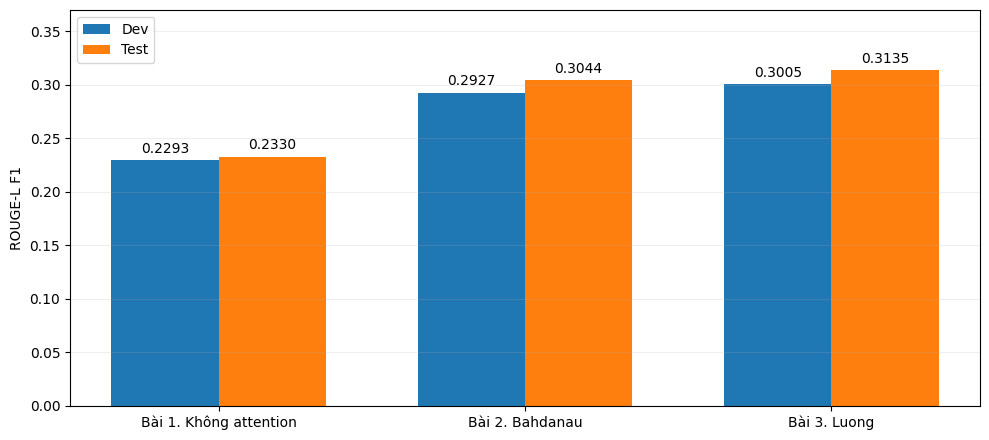

In [30]:
fig,ax = plt.subplots(figsize=(10,4.5))
x = np.arange(len(summary)); w=.35
for dx,col,name in [(-w/2,'dev_rougeL','Dev'),(w/2,'test_rougeL','Test')]:
    bars=ax.bar(x+dx,summary[col],w,label=name)
    ax.bar_label(bars,fmt='%.4f',padding=3)
ax.set_xticks(x,summary.model_label); ax.set_ylabel('ROUGE-L F1'); ax.set_ylim(0,min(1.12,max(.1,summary[['dev_rougeL','test_rougeL']].max().max()*1.18)))
ax.legend(); ax.grid(axis='y',alpha=.2); fig.tight_layout()
fig.savefig(ART/'comparison_rougeL.png',dpi=180,bbox_inches='tight'); plt.show(); plt.close(fig)

### 12.1. Nhận xét dựa trên số liệu thực nghiệm


In [31]:
s = summary.set_index('model')
best_test = s.test_rougeL.max()
winners = s.index[np.isclose(s.test_rougeL,best_test,atol=1e-12,rtol=0)].tolist()
best_dev = s.dev_rougeL.max()
dev_winners = s.index[np.isclose(s.dev_rougeL,best_dev,atol=1e-12,rtol=0)].tolist()
base = s.loc['none']
lines = [f'**Kết quả test:** {", ".join(LABELS[m] for m in winners)} đạt ROUGE-L cao nhất ({best_test:.4f}).',
         f'**Kết quả dev:** {", ".join(LABELS[m] for m in dev_winners)} đạt ROUGE-L cao nhất ({best_dev:.4f}).']
for mode in MODES:
    r=s.loc[mode]; h=pd.DataFrame(histories[mode]); delta=r.test_rougeL-base.test_rougeL
    lines.append(f'**{LABELS[mode]}:** loss epoch 1 → 10: {h.train_loss.iloc[0]:.4f} → {h.train_loss.iloc[-1]:.4f}; '
                 f'best epoch {best_epochs[mode]}; test trừ dev = {r.test_rougeL-r.dev_rougeL:+.4f}; '
                 f'{int(r.parameters):,} tham số; {r.seconds_per_epoch:.2f} giây/epoch.')
    if mode!='none':
        relation = 'cao hơn' if delta>0 else ('thấp hơn' if delta<0 else 'bằng')
        lines.append(f'So với baseline, ROUGE-L test {relation} (chênh lệch {delta:+.4f}, tức {100*delta:+.2f} điểm phần trăm); '
                     f'thêm {int(r.parameters-base.parameters):,} tham số, thời gian chênh {r.seconds_per_epoch-base.seconds_per_epoch:+.2f} giây/epoch.')
if winners == ['none']:
    lines.append('Baseline dẫn đầu: attention không bảo đảm cải thiện trong thiết lập này. Có thể liên quan đến độ khó tối ưu, dữ liệu và cách giải mã; cần nhiều seed để kiểm chứng.')
elif winners == ['bahdanau']:
    lines.append('Bahdanau dẫn đầu: khả năng tạo context từ trạng thái trước khi cập nhật LSTM có thể hỗ trợ sử dụng thông tin nguồn ở từng bước. Đây là giải thích khả dĩ, cần đối chiếu lỗi dịch và heatmap.')
elif winners == ['luong']:
    lines.append('Luong dẫn đầu: general attention sau cập nhật LSTM và input-feeding có thể hỗ trợ khai thác memory và thông tin attention qua các bước. Đây là giải thích khả dĩ, không phải kết luận nhân quả.')
else:
    lines.append('Có nhiều mô hình đồng hạng theo ROUGE-L test; không thể khẳng định một mô hình vượt trội.')
lines.append('ROUGE-L chỉ đo trùng khớp chuỗi; cần kết hợp phân tích câu dịch. Không dùng test để chỉnh siêu tham số; chỉ kết luận trong cấu hình và seed đã chạy.')
report_text='\n\n'.join(lines)
display(Markdown(report_text))
(ART/'discussion.md').write_text(report_text,encoding='utf-8')

**Kết quả test:** Bài 3. Luong đạt ROUGE-L cao nhất (0.3135).

**Kết quả dev:** Bài 3. Luong đạt ROUGE-L cao nhất (0.3005).

**Bài 1. Không attention:** loss epoch 1 → 10: 6.0187 → 4.8821; best epoch 9; test trừ dev = +0.0037; 7,500,963 tham số; 67.62 giây/epoch.

**Bài 2. Bahdanau:** loss epoch 1 → 10: 6.0384 → 4.4865; best epoch 10; test trừ dev = +0.0117; 8,025,763 tham số; 102.20 giây/epoch.

So với baseline, ROUGE-L test cao hơn (chênh lệch +0.0714, tức +7.14 điểm phần trăm); thêm 524,800 tham số, thời gian chênh +34.59 giây/epoch.

**Bài 3. Luong:** loss epoch 1 → 10: 6.0632 → 4.4763; best epoch 10; test trừ dev = +0.0130; 7,959,971 tham số; 92.25 giây/epoch.

So với baseline, ROUGE-L test cao hơn (chênh lệch +0.0805, tức +8.05 điểm phần trăm); thêm 459,008 tham số, thời gian chênh +24.64 giây/epoch.

Luong dẫn đầu: general attention sau cập nhật LSTM và input-feeding có thể hỗ trợ khai thác memory và thông tin attention qua các bước. Đây là giải thích khả dĩ, không phải kết luận nhân quả.

ROUGE-L chỉ đo trùng khớp chuỗi; cần kết hợp phân tích câu dịch. Không dùng test để chỉnh siêu tham số; chỉ kết luận trong cấu hình và seed đã chạy.

1160

## 13. Lưu sản phẩm và chuẩn bị nộp bài



In [32]:
expected_artifacts = ['metadata.json','comparison_dev.csv','comparison_test.csv','C2_summary.csv',
                      'learning_curves.png','comparison_rougeL.png','discussion.md','attention_analysis.csv']
for m in MODES:
    expected_artifacts += [f'{m}.pt',f'history_{m}.csv',f'learning_curves_{m}.png',
                           f'predictions_test_{m}.csv',f'samples_{m}.csv']
for i in range(1,4): expected_artifacts += [f'attention_bahdanau_{i}.png']
assert all((ART/f).is_file() for f in expected_artifacts)
print('Đủ các tệp kết quả chính:',ART)
display(pd.DataFrame([{'file':p.name,'size_KiB':round(p.stat().st_size/1024,1)}
                      for p in sorted(ART.iterdir()) if p.is_file()]))

Đủ các tệp kết quả chính: /kaggle/working/lab4_artifacts


,file,size_KiB
0,C2_summary.csv,0.3
1,attention_alignment_1.csv,0.2
2,attention_alignment_2.csv,1.1
3,attention_alignment_3.csv,0.6
4,attention_analysis.csv,1.3
5,attention_bahdanau_1.png,56.6
6,attention_bahdanau_2.png,159.2
7,attention_bahdanau_3.png,100.1
8,attention_matrix_1.npy,0.2
9,attention_matrix_2.npy,4.9
